In [ ]:
# Autor: Victor Jefferson Cardoso Moreira
# Oriendador: José Jadsom Sampaio de Figueiredo
# Curso: Geofísica
# Instituição: Universidade Federal do Pará

# O código tem como finalidade aplicação de mascara na amostra, remoção das regiões indesejaveis, aplicação de clusters para separação dos grãos e preenchimentos das lacunas existentes após o filtros

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from skimage import io, measure, morphology
from scipy.ndimage import binary_fill_holes
from skimage.morphology import remove_small_holes
from skimage.io import imsave

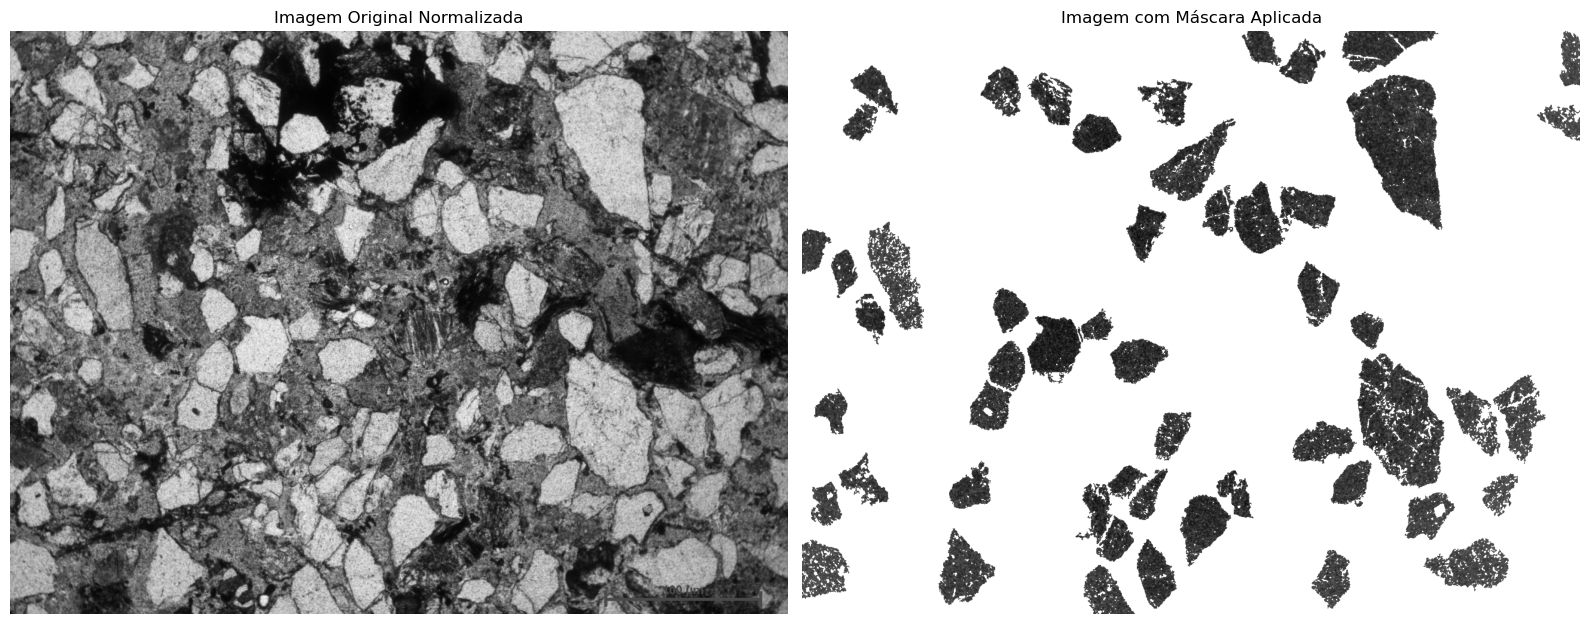

In [2]:
def apply_mask_by_pixel_range(image_path, output_folder, pixel_range, min_grain_size=2500):
    """
    Aplica uma máscara considerando regiões conectadas de pixels dentro de um intervalo específico de intensidade.

    :param image_path: Caminho para a imagem de entrada.
    :param output_folder: Pasta onde a imagem processada será salva.
    :param pixel_range: Tupla (min_intensidade, max_intensidade) para valores de pixel a considerar como grãos.
    :param min_grain_size: Tamanho mínimo (em pixels) para considerar como grão.
    :return: A imagem original normalizada e a imagem mascarada.
    """
    # Carregar a imagem no formato de escala de cinza
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError("Não foi possível carregar a imagem. Verifique o caminho e o formato do arquivo.")
    
    # Normalizar a imagem de 0 a 1 e depois para o intervalo [0, 255]
    normalized_image = cv2.normalize(image, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX).astype(np.uint8)
    
    # Criar uma máscara para o intervalo de valores de pixel
    mask = cv2.inRange(normalized_image, pixel_range[0], pixel_range[1])
    
    # Identificar regiões conectadas na máscara
    labeled_image = measure.label(mask, connectivity=1)
    properties = measure.regionprops(labeled_image)
    
    # Criar uma máscara final considerando apenas regiões acima do tamanho mínimo
    final_mask = np.zeros_like(mask, dtype=np.uint8)
    for prop in properties:
        if prop.area >= min_grain_size:
            final_mask[labeled_image == prop.label] = 255
    
    # Aplicar a máscara final na imagem original
    masked_image = cv2.bitwise_and(normalized_image, normalized_image, mask=final_mask)
    
    # Criar a pasta de saída se não existir
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)
    
    # Salvar a imagem mascarada em formato .tif
    output_path = os.path.join(output_folder, "amostra_02.tif")
    io.imsave(output_path, masked_image)
    
    return normalized_image, masked_image

# Parâmetros
image_path = "amostra_02.jpg"  # Substituir pelo caminho da sua imagem
output_folder = "mascara_filtrada"
pixel_range = (155, 250)  # Intervalo de valores de pixel para considerar como grãos
min_grain_size = 2000     # Tamanho mínimo de grãos (em pixels)

# Executar a função
normalized_image, masked_image = apply_mask_by_pixel_range(image_path, output_folder, pixel_range, min_grain_size)

# Mostrar as imagens e as análises
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.title("Imagem Original Normalizada")
plt.imshow(normalized_image, cmap="gray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title("Imagem com Máscara Aplicada")
plt.imshow(masked_image, cmap="gray_r")
plt.axis("off")
plt.tight_layout()
plt.show()

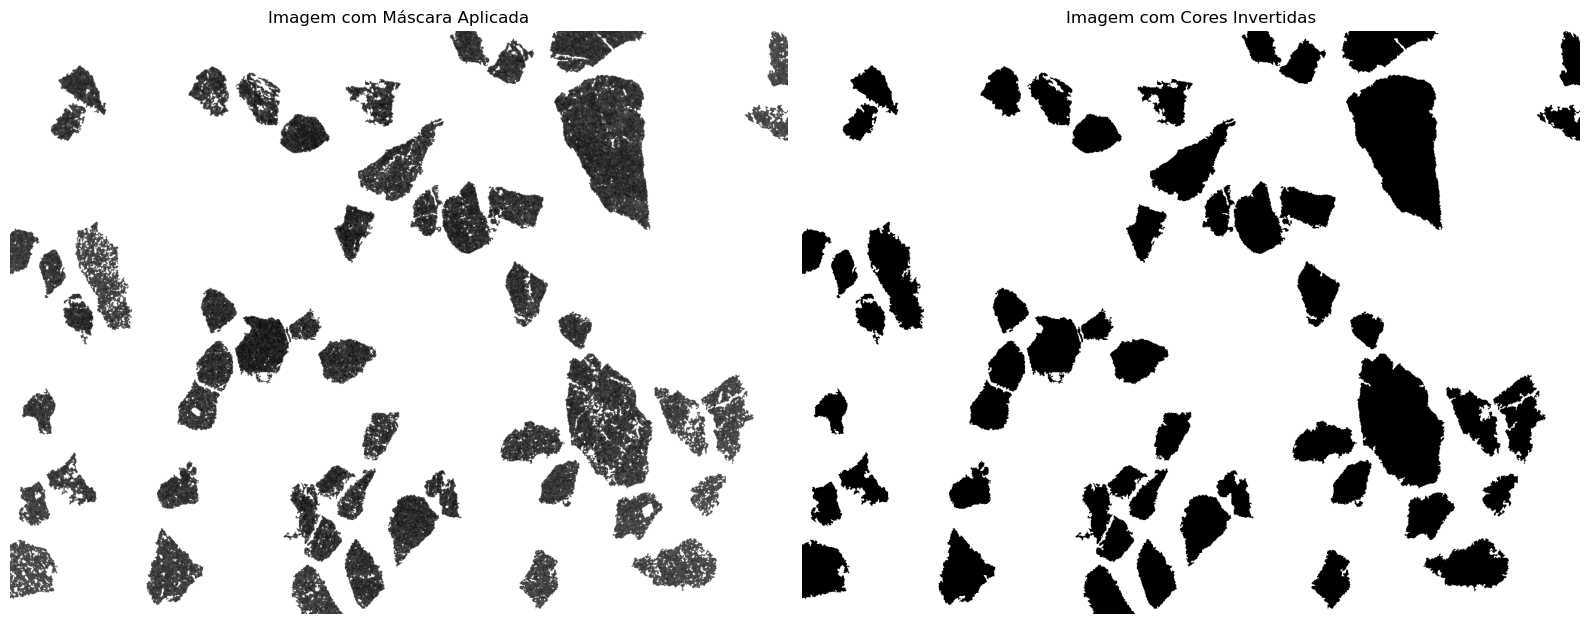

Imagem salva em: amostra_02_mascara/amostra_02_trashhold_20.tif


In [3]:
def cluster_and_fill_grains(masked_image, eps=10, min_samples=10):
    """
    Clusteriza e preenche lacunas dentro dos grãos da imagem.

    :param masked_image: Imagem com a máscara aplicada (grãos).
    :param eps: Distância máxima entre dois pontos para que sejam considerados no mesmo cluster (DBSCAN).
    :param min_samples: Número mínimo de pontos para formar um cluster (DBSCAN).
    :return: Imagem com grãos agrupados e lacunas preenchidas.
    """
    # Encontra os pixels não nulos na imagem (regiões com grãos)
    y_coords, x_coords = np.nonzero(masked_image)
    coordinates = np.column_stack((x_coords, y_coords))  # Coordenadas (x, y) dos grãos

    # Clusterização dos grãos usando DBSCAN
    clustering = DBSCAN(eps=eps, min_samples=min_samples).fit(coordinates)
    labels = clustering.labels_

    # Cria uma imagem para os clusters
    clustered_image = np.zeros_like(masked_image, dtype=np.uint8)
    for label in set(labels):
        if label != -1:  # Ignora pontos fora de clusters
            cluster_points = coordinates[labels == label]
            for x, y in cluster_points:
                clustered_image[y, x] = 255  # Marca os clusters com valores de intensidade

    # Preenchimento de lacunas nos grãos
    filled_image = binary_fill_holes(clustered_image).astype(np.uint8) * 255

    # Remoção de pequenos buracos que podem ter sobrado
    final_image = remove_small_holes(filled_image.astype(bool), area_threshold=64).astype(np.uint8) * 255

    return clustered_image, final_image

# Clusterização e preenchimento
clustered_image, filled_image = cluster_and_fill_grains(masked_image, eps=50, min_samples=50)

# Inverter as cores da imagem
inverted_image = 255 - filled_image

# Mostrar as imagens processadas
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.title("Imagem com Máscara Aplicada")
plt.imshow(masked_image, cmap="gray_r")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title("Imagem com Cores Invertidas")
plt.imshow(inverted_image, cmap="gray")
plt.axis("off")
plt.tight_layout()
plt.show()

# Salvar a imagem invertida em uma pasta no formato .tif
output_dir = "amostra_02_mascara"  # Nome da pasta
os.makedirs(output_dir, exist_ok=True)  # Criar a pasta se não existir
output_path = os.path.join(output_dir, "amostra_02_trashhold_20.tif")  # Caminho do arquivo

# Salvar a imagem invertida no formato .tif
imsave(output_path, inverted_image)
print(f"Imagem salva em: {output_path}")


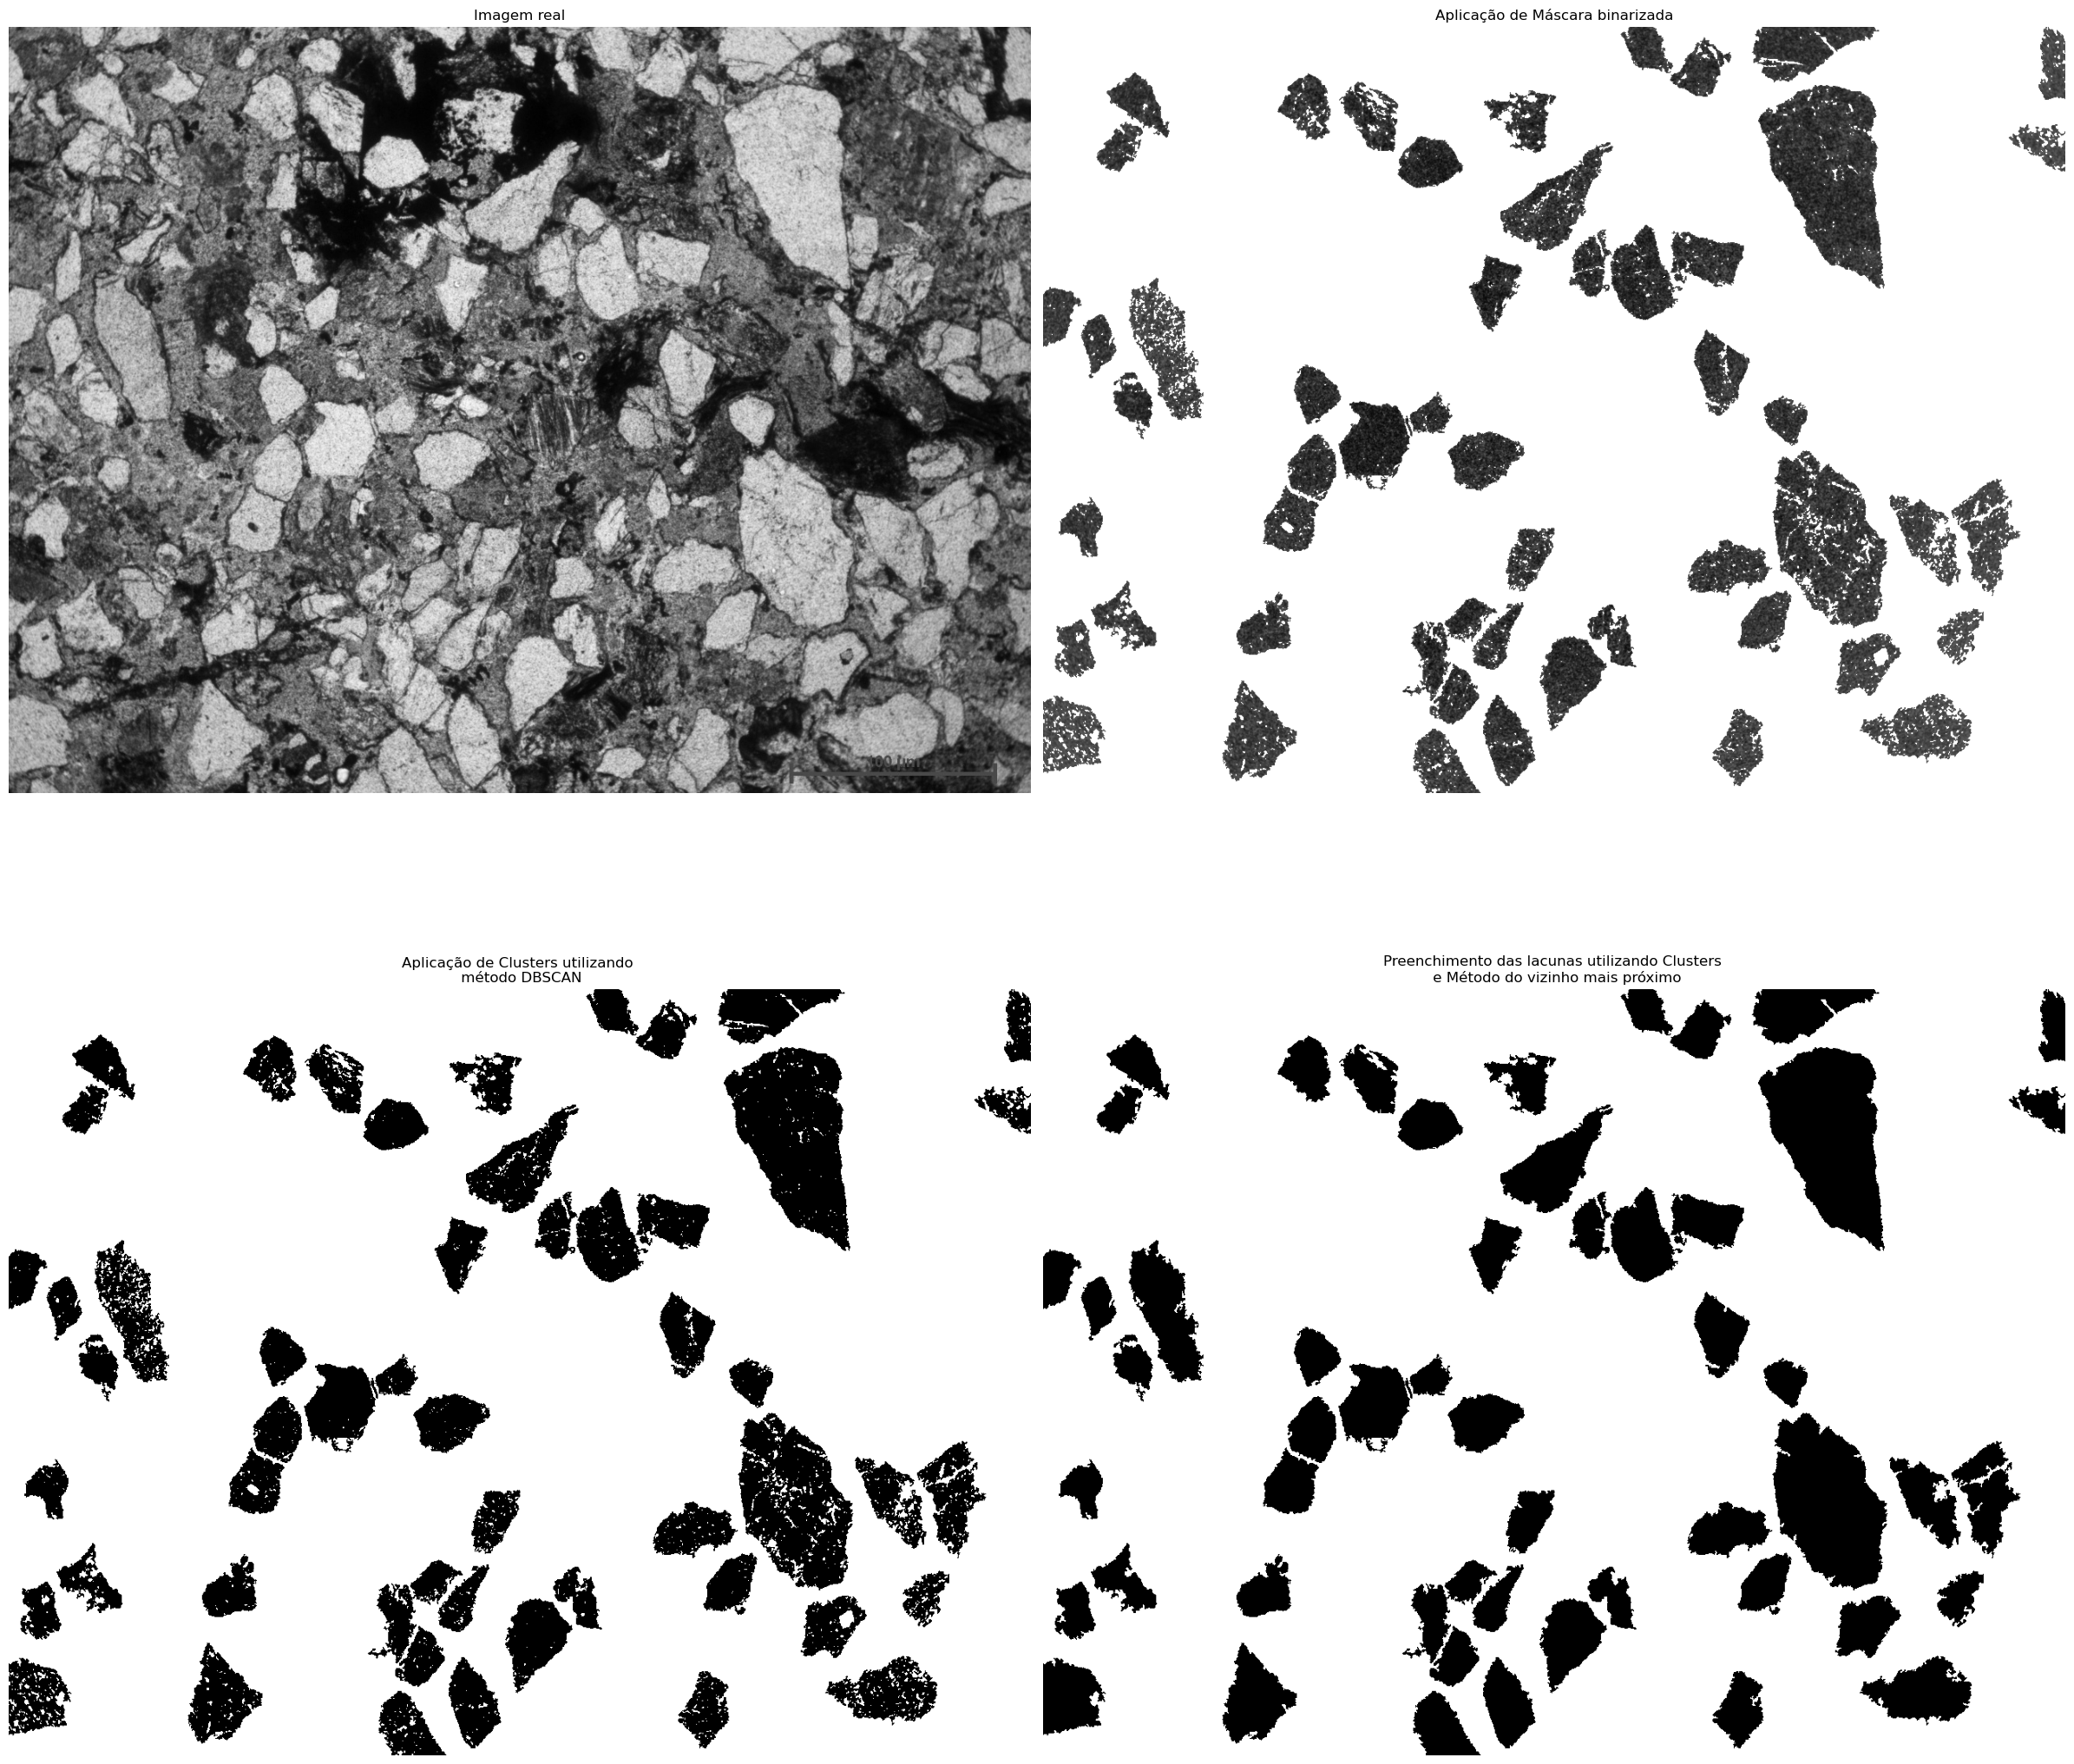

In [4]:
# Mostrar as imagens processadas em 2 linhas e 2 colunas
plt.figure(figsize=(24, 24))

# Imagem original com máscara aplicada
plt.subplot(2, 2, 1)
plt.title("Imagem real")
plt.imshow(normalized_image, cmap="gray")
plt.axis("off")

# Imagem dos grãos clusterizados
plt.subplot(2, 2, 2)
plt.title("Aplicação de Máscara binarizada")
plt.imshow(masked_image, cmap="gray_r")
plt.axis("off")

# Imagem final preenchida
plt.subplot(2, 2, 3)
plt.title("Aplicação de Clusters utilizando \n método DBSCAN")
plt.imshow(clustered_image, cmap="gray_r")
plt.axis("off")

# Imagem final com cores invertidas
plt.subplot(2, 2, 4)
plt.title("Preenchimento das lacunas utilizando Clusters \n e Método do vizinho mais próximo")
plt.imshow(inverted_image, cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()
